# Tuned, Pipelined Churn Classification with Imbalance Handling and Error Analysis

Run every cell from top to bottom (Runtime > Run all). The dataset `WA_Fn-UseC_-Telco-Customer-Churn.csv` is requested by the upload cell if it is not already present.

## 1. Install

In [1]:
!pip install -q -U xgboost


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\HP 840 G5\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


## 2. Imports

In [2]:
import time
import warnings
from pathlib import Path

import joblib
import matplotlib

matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint, uniform
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

## 3. Configuration

In [3]:
SEED = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
N_ITER = 25
MIN_RECALL = 0.85
MIN_SEGMENT_SIZE = 30
MIN_GROUP_SUPPORT = 15
DEFAULT_THRESHOLD = 0.5

DATA_NAME = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
NUMERIC_COLS = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
SEGMENT_COLS = [
    "Contract",
    "tenure_band",
    "InternetService",
    "PaymentMethod",
    "PaperlessBilling",
    "SeniorCitizen",
]
SAMPLE_COLS = [
    "customerID",
    "error_type",
    "proba",
    "tenure",
    "Contract",
    "InternetService",
    "PaymentMethod",
    "MonthlyCharges",
    "TechSupport",
]
STRATEGIES = ["baseline", "scale_pos_weight", "random_oversampling"]
CANDIDATE_STRATEGIES = ["scale_pos_weight", "random_oversampling"]

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()

OUTPUT_DIR = BASE_DIR / "outputs"
MODEL_DIR = BASE_DIR / "models"

## 4. Data loading and splitting

In [4]:
def find_data():
    candidates = [
        BASE_DIR / "data" / DATA_NAME,
        BASE_DIR / DATA_NAME,
        Path.cwd() / "data" / DATA_NAME,
        Path.cwd() / DATA_NAME,
        Path("/content") / DATA_NAME,
        Path("/content/data") / DATA_NAME,
    ]
    for path in candidates:
        if path.exists():
            return path
    for folder in [BASE_DIR, BASE_DIR / "data", Path.cwd(), Path.cwd() / "data"]:
        if folder.exists():
            found = sorted(folder.glob("*Telco*Churn*.csv"))
            if found:
                return found[0]
    raise FileNotFoundError(
        f"{DATA_NAME} not found. Put it in the data folder next to this script."
    )


def load_data():
    df = pd.read_csv(find_data())
    df.columns = [c.strip() for c in df.columns]
    for col in df.columns:
        if not pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].astype(str).str.strip()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df["SeniorCitizen"] = df["SeniorCitizen"].astype(int)
    ids = df["customerID"].copy()
    y = (df["Churn"] == "Yes").astype(int)
    X = df.drop(columns=["customerID", "Churn"])
    return X, y, ids


def split_data(X, y, ids):
    return train_test_split(
        X, y, ids, test_size=TEST_SIZE, stratify=y, random_state=SEED
    )

## 5. Locate the dataset

In [5]:
try:
    DATA_PATH = find_data()
    print("Dataset found:", DATA_PATH)
except FileNotFoundError:
    from google.colab import files

    files.upload()
    DATA_PATH = find_data()
    print("Dataset found:", DATA_PATH)

Dataset found: c:\Users\HP 840 G5\OneDrive\Desktop\churn_project\data\WA_Fn-UseC_-Telco-Customer-Churn.csv


## 6. Pipeline, imbalance strategies and tuning

In [6]:
class RandomOversampledClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, estimator=None, sampling_ratio=1.0, random_state=42):
        self.estimator = estimator
        self.sampling_ratio = sampling_ratio
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        rng = np.random.default_rng(self.random_state)
        positive = np.flatnonzero(y == 1)
        negative = np.flatnonzero(y == 0)
        target = int(round(len(negative) * self.sampling_ratio))
        extra = rng.choice(positive, size=max(target - len(positive), 0), replace=True)
        index = np.concatenate([np.arange(len(y)), extra])
        self.estimator_ = clone(self.estimator).fit(X[index], y[index])
        self.classes_ = self.estimator_.classes_
        return self

    def predict_proba(self, X):
        return self.estimator_.predict_proba(np.asarray(X))

    def predict(self, X):
        return self.estimator_.predict(np.asarray(X))


def make_xgb(scale_pos_weight):
    return XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=1,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=1,
        random_state=SEED,
        verbosity=0,
    )


def build_preprocessor(numeric_cols, categorical_cols):
    numeric = Pipeline(
        [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    )
    categorical = Pipeline(
        [
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    return ColumnTransformer(
        [("num", numeric, numeric_cols), ("cat", categorical, categorical_cols)]
    )


def build_pipeline(strategy, X, scale_pos_weight):
    numeric_cols = [c for c in NUMERIC_COLS if c in X.columns]
    categorical_cols = [c for c in X.columns if c not in numeric_cols]
    if strategy == "baseline":
        model = make_xgb(1.0)
    elif strategy == "scale_pos_weight":
        model = make_xgb(scale_pos_weight)
    elif strategy == "random_oversampling":
        model = RandomOversampledClassifier(
            estimator=make_xgb(1.0), sampling_ratio=1.0, random_state=SEED
        )
    else:
        raise ValueError(f"Unknown strategy: {strategy}")
    return Pipeline(
        [
            ("prep", build_preprocessor(numeric_cols, categorical_cols)),
            ("model", model),
        ]
    )


def param_space(strategy):
    prefix = "model__estimator__" if strategy == "random_oversampling" else "model__"
    space = {
        "n_estimators": randint(150, 600),
        "max_depth": randint(2, 7),
        "learning_rate": loguniform(0.01, 0.2),
        "subsample": uniform(0.6, 0.4),
        "colsample_bytree": uniform(0.5, 0.5),
        "min_child_weight": randint(1, 10),
    }
    return {prefix + name: dist for name, dist in space.items()}


def tune(strategy, X_train, y_train, scale_pos_weight):
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    search = RandomizedSearchCV(
        estimator=build_pipeline(strategy, X_train, scale_pos_weight),
        param_distributions=param_space(strategy),
        n_iter=N_ITER,
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
        random_state=SEED,
        refit=True,
    )
    search.fit(X_train, y_train)
    return search

## 7. Metrics, threshold selection and plots

In [7]:
def compute_metrics(y_true, proba, threshold):
    y_true = np.asarray(y_true)
    proba = np.asarray(proba)
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "tn": int(tn),
    }


def out_of_fold_probabilities(pipeline, X_train, y_train):
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED + 1)
    proba = cross_val_predict(
        pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
    )
    return proba[:, 1]


def select_threshold(y_true, proba, min_recall):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    precision = precision[:-1]
    recall = recall[:-1]
    feasible = recall >= min_recall
    if feasible.any():
        candidates = np.flatnonzero(feasible)
        best = candidates[np.argmax(precision[candidates])]
    else:
        f2 = 5 * precision * recall / (4 * precision + recall + 1e-12)
        best = int(np.argmax(f2))
    return float(thresholds[best])


def plot_pr_curves(y_test, probas, selected, threshold, path):
    fig, ax = plt.subplots(figsize=(8, 6))
    for name, proba in probas.items():
        precision, recall, _ = precision_recall_curve(y_test, proba)
        ap = average_precision_score(y_test, proba)
        width = 2.5 if name == selected else 1.4
        ax.plot(recall, precision, linewidth=width, label=f"{name} (PR-AUC {ap:.3f})")
    ax.axhline(
        float(np.mean(y_test)), linestyle="--", color="gray", label="No-skill baseline"
    )
    default_point = compute_metrics(y_test, probas[selected], DEFAULT_THRESHOLD)
    chosen_point = compute_metrics(y_test, probas[selected], threshold)
    ax.scatter(
        default_point["recall"],
        default_point["precision"],
        color="black",
        zorder=5,
        label=f"Default threshold {DEFAULT_THRESHOLD:.2f}",
    )
    ax.scatter(
        chosen_point["recall"],
        chosen_point["precision"],
        color="red",
        marker="*",
        s=220,
        zorder=6,
        label=f"Chosen threshold {threshold:.3f}",
    )
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title("Precision-Recall curves on the hold-out set")
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def plot_threshold_tradeoff(y_true, proba, threshold, path):
    grid = np.linspace(0.05, 0.95, 91)
    rows = [compute_metrics(y_true, proba, t) for t in grid]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(grid, [r["precision"] for r in rows], label="Precision")
    ax.plot(grid, [r["recall"] for r in rows], label="Recall")
    ax.plot(grid, [r["f1"] for r in rows], label="F1")
    ax.axvline(DEFAULT_THRESHOLD, color="black", linestyle=":", label="Default 0.5")
    ax.axvline(threshold, color="red", linestyle="--", label=f"Chosen {threshold:.3f}")
    ax.axhline(MIN_RECALL, color="gray", linestyle="--", alpha=0.6)
    ax.set_xlabel("Decision threshold")
    ax.set_ylabel("Score")
    ax.set_title("Threshold trade-off on out-of-fold training predictions")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)

## 8. Error analysis helpers

In [8]:
def build_error_frame(X_test, y_test, ids_test, proba, threshold):
    frame = X_test.reset_index(drop=True).copy()
    frame.insert(0, "customerID", ids_test.reset_index(drop=True).values)
    frame["actual"] = np.asarray(y_test)
    frame["proba"] = np.asarray(proba)
    frame["pred"] = (frame["proba"] >= threshold).astype(int)
    frame["tenure_band"] = pd.cut(
        frame["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"],
    ).astype(str)
    frame["error_type"] = np.select(
        [
            (frame["actual"] == 1) & (frame["pred"] == 0),
            (frame["actual"] == 0) & (frame["pred"] == 1),
        ],
        ["False Negative", "False Positive"],
        default="Correct",
    )
    return frame


def segment_error_table(frame):
    rows = []
    for col in SEGMENT_COLS:
        for value, group in frame.groupby(col):
            churners = int((group["actual"] == 1).sum())
            stayers = int((group["actual"] == 0).sum())
            fn = int((group["error_type"] == "False Negative").sum())
            fp = int((group["error_type"] == "False Positive").sum())
            rows.append(
                {
                    "feature": col,
                    "value": str(value),
                    "customers": len(group),
                    "churners": churners,
                    "false_negatives": fn,
                    "fn_rate": fn / churners if churners else np.nan,
                    "stayers": stayers,
                    "false_positives": fp,
                    "fp_rate": fp / stayers if stayers else np.nan,
                    "error_rate": (fn + fp) / len(group),
                }
            )
    table = pd.DataFrame(rows)
    return table[table["customers"] >= MIN_SEGMENT_SIZE].reset_index(drop=True)


def sample_misclassified(frame, per_type=5):
    false_negatives = frame[frame["error_type"] == "False Negative"].sort_values("proba")
    false_positives = frame[frame["error_type"] == "False Positive"].sort_values(
        "proba", ascending=False
    )
    take_fn = min(per_type, len(false_negatives))
    take_fp = min(per_type, len(false_positives))
    remaining = 2 * per_type - take_fn - take_fp
    if remaining > 0:
        if len(false_negatives) > take_fn:
            take_fn += min(remaining, len(false_negatives) - take_fn)
        elif len(false_positives) > take_fp:
            take_fp += min(remaining, len(false_positives) - take_fp)
    sample = pd.concat([false_negatives.head(take_fn), false_positives.head(take_fp)])
    return sample[SAMPLE_COLS].reset_index(drop=True)


def top_value(series):
    counts = series.value_counts()
    return f"{counts.index[0]} ({counts.iloc[0]} of {len(series)})"


def describe_sample_group(group):
    return (
        f"median tenure {group['tenure'].median():.0f} months, "
        f"most common contract {top_value(group['Contract'])}, "
        f"internet service {top_value(group['InternetService'])}, "
        f"payment method {top_value(group['PaymentMethod'])}, "
        f"median monthly charge {group['MonthlyCharges'].median():.2f}, "
        f"mean predicted churn probability {group['proba'].mean():.2f}"
    )


def find_patterns(segments, frame):
    churners = int((frame["actual"] == 1).sum())
    stayers = int((frame["actual"] == 0).sum())
    overall_fn = float((frame["error_type"] == "False Negative").sum() / churners)
    overall_fp = float((frame["error_type"] == "False Positive").sum() / stayers)
    fn_candidates = (
        segments[segments["churners"] >= MIN_GROUP_SUPPORT]
        .sort_values("fn_rate", ascending=False)
        .head(3)
    )
    fp_candidates = (
        segments[segments["stayers"] >= MIN_GROUP_SUPPORT]
        .sort_values("fp_rate", ascending=False)
        .head(3)
    )
    fn_patterns = [
        (
            f"Churners with {r.feature} = {r.value} are missed {r.fn_rate:.0%} of the time "
            f"({r.false_negatives} of {r.churners}), against {overall_fn:.0%} overall."
        )
        for r in fn_candidates.itertuples()
    ]
    fp_patterns = [
        (
            f"Customers who stay with {r.feature} = {r.value} are wrongly flagged "
            f"{r.fp_rate:.0%} of the time ({r.false_positives} of {r.stayers}), "
            f"against {overall_fp:.0%} overall."
        )
        for r in fp_candidates.itertuples()
    ]
    return overall_fn, overall_fp, fn_patterns, fp_patterns

## 9. Report writers

In [9]:
def df_to_md(df, digits=4):
    columns = list(df.columns)
    lines = [
        "| " + " | ".join(str(c) for c in columns) + " |",
        "| " + " | ".join("---" for _ in columns) + " |",
    ]
    for row in df.itertuples(index=False):
        cells = []
        for value in row:
            if isinstance(value, (float, np.floating)):
                cells.append(f"{value:.{digits}f}")
            else:
                cells.append(str(value))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)


def metrics_table(entries):
    rows = []
    for label, m in entries:
        rows.append(
            {
                "setting": label,
                "threshold": m["threshold"],
                "precision": m["precision"],
                "recall": m["recall"],
                "f1": m["f1"],
                "tp": m["tp"],
                "fp": m["fp"],
                "fn": m["fn"],
                "tn": m["tn"],
            }
        )
    return pd.DataFrame(rows)


def write_threshold_report(path, ctx):
    t = ctx["threshold"]
    direction = "higher" if t > DEFAULT_THRESHOLD else "lower"
    comparison = ctx["comparison"][
        ["strategy", "cv_pr_auc", "precision", "recall", "f1", "roc_auc", "pr_auc"]
    ]
    oof_table = metrics_table(
        [
            ("Train out-of-fold, default", ctx["oof_default"]),
            ("Train out-of-fold, chosen", ctx["oof_chosen"]),
        ]
    )
    holdout_table = metrics_table(
        [
            ("Hold-out, default", ctx["holdout_default"]),
            ("Hold-out, chosen", ctx["holdout_chosen"]),
        ]
    )
    params = "\n".join(f"- `{k}`: {v}" for k, v in sorted(ctx["best_params"].items()))
    text = f"""# Threshold Decision

## Business preference

The model is used to decide which customers receive a retention offer. Missing a customer who is about to leave (a false negative) costs that customer's future revenue, while contacting a customer who would have stayed (a false positive) only costs one offer. Recall is therefore prioritised over precision.

Decision rule: choose the threshold with the highest precision among all thresholds that keep recall at or above {MIN_RECALL:.0%}.

## Imbalance strategy comparison

All three strategies were tuned with the same {CV_FOLDS}-fold stratified RandomizedSearchCV ({N_ITER} candidates, scored by PR-AUC). Resampling happens only inside the training folds, so the hold-out set is never resampled. Metrics below are on the untouched hold-out set at the default 0.5 threshold. The strategy was selected by cross-validated PR-AUC on training data only.

{df_to_md(comparison)}

Selected strategy: **{ctx["selected"]}**

Best hyperparameters:

{params}

## How the threshold was chosen

The threshold was picked from out-of-fold predicted probabilities on the training data, so the hold-out set played no part in the choice. It was then applied once to the hold-out set.

Chosen threshold: **{t:.4f}** ({direction} than the default {DEFAULT_THRESHOLD:.2f}).

{df_to_md(oof_table)}

## Hold-out results

{df_to_md(holdout_table)}

Hold-out size: {ctx["n_holdout"]} customers, {ctx["n_holdout_churn"]} of them churners.

## What the threshold implies

Compared with the default threshold, {t:.4f} flags {ctx["holdout_chosen"]["tp"] + ctx["holdout_chosen"]["fp"] - ctx["holdout_default"]["tp"] - ctx["holdout_default"]["fp"]:+d} customers on the hold-out set and changes the number of caught churners by {ctx["holdout_chosen"]["tp"] - ctx["holdout_default"]["tp"]:+d}. The model's probabilities are not calibrated, particularly when class weighting is used, so the threshold is a ranking cutoff and should not be read as a literal probability of churn. If a retention offer is cheap relative to lost revenue the threshold should move down, and if offers are expensive it should move up.

## Figures

- `outputs/pr_curves.png`: precision-recall curves with the default and chosen operating points marked.
- `outputs/threshold_tradeoff.png`: precision, recall and F1 against the threshold on out-of-fold predictions.

## Caveats

Recall on the hold-out set can differ from the {MIN_RECALL:.0%} target because the threshold was fitted on different data. With {ctx["n_holdout_churn"]} churners in the hold-out set, small differences in recall are within normal sampling noise.
"""
    Path(path).write_text(text, encoding="utf-8")


def write_error_report(path, ctx):
    sample = ctx["sample"]
    sample_table = sample.copy()
    sample_table["proba"] = sample_table["proba"].round(3)
    sample_table["MonthlyCharges"] = sample_table["MonthlyCharges"].round(2)
    group_lines = []
    for error_type in ["False Negative", "False Positive"]:
        subset = sample[sample["error_type"] == error_type]
        if len(subset):
            group_lines.append(
                f"- **{error_type}s ({len(subset)} customers):** {describe_sample_group(subset)}."
            )
    grouped = (
        sample.groupby(["error_type", "Contract", "InternetService"])
        .size()
        .reset_index(name="customers")
        .sort_values(["error_type", "customers"], ascending=[True, False])
    )
    fn_patterns = "\n".join(f"{i}. {p}" for i, p in enumerate(ctx["fn_patterns"], 1))
    fp_patterns = "\n".join(f"{i}. {p}" for i, p in enumerate(ctx["fp_patterns"], 1))
    segments = ctx["segments"]
    columns = ["feature", "value", "customers", "churners", "fn_rate", "stayers", "fp_rate"]
    fn_table = (
        segments[segments["churners"] >= MIN_GROUP_SUPPORT]
        .sort_values("fn_rate", ascending=False)
        .head(8)[columns]
    )
    fp_table = (
        segments[segments["stayers"] >= MIN_GROUP_SUPPORT]
        .sort_values("fp_rate", ascending=False)
        .head(8)[columns]
    )
    m = ctx["metrics"]
    text = f"""# Error Analysis

## Setup

- Model: `{ctx["selected"]}` strategy, decision threshold {ctx["threshold"]:.4f}
- Hold-out customers: {ctx["n_holdout"]}
- Confusion matrix: TP {m["tp"]}, FP {m["fp"]}, FN {m["fn"]}, TN {m["tn"]}
- Share of churners missed (false negative rate): {ctx["overall_fn"]:.1%}
- Share of stayers wrongly flagged (false positive rate): {ctx["overall_fp"]:.1%}

## Ten misclassified customers

The five most confident false negatives (churners given the lowest churn probability) and the five most confident false positives (stayers given the highest churn probability).

{df_to_md(sample_table, digits=3)}

## Grouping by shared characteristics

{chr(10).join(group_lines)}

Counts by error type, contract and internet service:

{df_to_md(grouped)}

## Patterns across the full hold-out set

Segments below have at least {MIN_SEGMENT_SIZE} customers and at least {MIN_GROUP_SUPPORT} customers of the relevant class.

### Where the model misses churners

{fn_patterns}

{df_to_md(fn_table, digits=3)}

### Where the model raises false alarms

{fp_patterns}

{df_to_md(fp_table, digits=3)}

## Takeaways

- The segments above show where errors concentrate. A segment with a miss rate far above the overall rate is where the model has the least signal.
- Segment-level rates rest on small counts, so treat them as leads to investigate rather than firm conclusions.
- Full per-segment numbers are in `outputs/segment_error_rates.csv` and the ten sampled customers are in `outputs/misclassified_sample.csv`.
"""
    Path(path).write_text(text, encoding="utf-8")

## 10. Main workflow

In [10]:
def main():
    started = time.time()
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)

    X, y, ids = load_data()
    X_train, X_test, y_train, y_test, ids_train, ids_test = split_data(X, y, ids)
    scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
    print(f"Rows: {len(X)} | train: {len(X_train)} | hold-out: {len(X_test)}")
    print(f"Churn rate: {y.mean():.3f} | scale_pos_weight: {scale_pos_weight:.3f}")

    searches = {}
    probas = {}
    rows = []
    for strategy in STRATEGIES:
        print(f"Tuning strategy: {strategy}")
        search = tune(strategy, X_train, y_train, scale_pos_weight)
        searches[strategy] = search
        probas[strategy] = search.best_estimator_.predict_proba(X_test)[:, 1]
        metrics = compute_metrics(y_test, probas[strategy], DEFAULT_THRESHOLD)
        rows.append({"strategy": strategy, "cv_pr_auc": search.best_score_, **metrics})
    comparison = pd.DataFrame(rows)
    comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
    print(comparison[["strategy", "cv_pr_auc", "precision", "recall", "f1", "roc_auc", "pr_auc"]].round(4).to_string(index=False))

    candidates = comparison[comparison["strategy"].isin(CANDIDATE_STRATEGIES)]
    selected = candidates.sort_values("cv_pr_auc", ascending=False).iloc[0]["strategy"]
    best_pipeline = searches[selected].best_estimator_
    print(f"Selected strategy: {selected}")

    oof = out_of_fold_probabilities(best_pipeline, X_train, y_train)
    threshold = select_threshold(y_train, oof, MIN_RECALL)
    print(f"Chosen threshold: {threshold:.4f}")

    oof_default = compute_metrics(y_train, oof, DEFAULT_THRESHOLD)
    oof_chosen = compute_metrics(y_train, oof, threshold)
    holdout_default = compute_metrics(y_test, probas[selected], DEFAULT_THRESHOLD)
    holdout_chosen = compute_metrics(y_test, probas[selected], threshold)

    plot_pr_curves(y_test, probas, selected, threshold, OUTPUT_DIR / "pr_curves.png")
    plot_threshold_tradeoff(y_train, oof, threshold, OUTPUT_DIR / "threshold_tradeoff.png")

    frame = build_error_frame(X_test, y_test, ids_test, probas[selected], threshold)
    segments = segment_error_table(frame)
    sample = sample_misclassified(frame)
    overall_fn, overall_fp, fn_patterns, fp_patterns = find_patterns(segments, frame)
    segments.to_csv(OUTPUT_DIR / "segment_error_rates.csv", index=False)
    sample.to_csv(OUTPUT_DIR / "misclassified_sample.csv", index=False)
    frame.to_csv(OUTPUT_DIR / "holdout_predictions.csv", index=False)

    best_params = {
        k.replace("model__estimator__", "").replace("model__", ""): (
            round(float(v), 5) if isinstance(v, (float, np.floating)) else int(v)
        )
        for k, v in searches[selected].best_params_.items()
    }
    context = {
        "selected": selected,
        "threshold": threshold,
        "comparison": comparison,
        "best_params": best_params,
        "oof_default": oof_default,
        "oof_chosen": oof_chosen,
        "holdout_default": holdout_default,
        "holdout_chosen": holdout_chosen,
        "n_holdout": len(X_test),
        "n_holdout_churn": int(np.sum(y_test)),
        "metrics": holdout_chosen,
        "sample": sample,
        "segments": segments,
        "overall_fn": overall_fn,
        "overall_fp": overall_fp,
        "fn_patterns": fn_patterns,
        "fp_patterns": fp_patterns,
    }
    write_threshold_report(BASE_DIR / "THRESHOLD_DECISION.md", context)
    write_error_report(BASE_DIR / "ERROR_ANALYSIS.md", context)

    joblib.dump(
        {"pipeline": best_pipeline, "threshold": threshold, "strategy": selected},
        MODEL_DIR / "churn_pipeline.joblib",
    )

    print(f"Hold-out at 0.5: {holdout_default}")
    print(f"Hold-out at {threshold:.4f}: {holdout_chosen}")
    print(f"Finished in {time.time() - started:.0f} seconds")
    return context


## 11. Run everything

In [11]:
results = main()

Rows: 7043 | train: 5634 | hold-out: 1409
Churn rate: 0.265 | scale_pos_weight: 2.769
Tuning strategy: baseline
Tuning strategy: scale_pos_weight
Tuning strategy: random_oversampling
           strategy  cv_pr_auc  precision  recall     f1  roc_auc  pr_auc
           baseline     0.6724     0.6760  0.5187 0.5870   0.8487  0.6660
   scale_pos_weight     0.6713     0.5190  0.8021 0.6303   0.8476  0.6645
random_oversampling     0.6698     0.5274  0.7968 0.6347   0.8485  0.6646
Selected strategy: scale_pos_weight
Chosen threshold: 0.4328
Hold-out at 0.5: {'threshold': 0.5, 'precision': 0.5190311418685121, 'recall': 0.8021390374331551, 'f1': 0.6302521008403361, 'roc_auc': 0.8475819576842595, 'pr_auc': 0.6644882098581177, 'tp': 300, 'fp': 278, 'fn': 74, 'tn': 757}
Hold-out at 0.4328: {'threshold': 0.4328339099884033, 'precision': 0.4823348694316436, 'recall': 0.839572192513369, 'f1': 0.6126829268292683, 'roc_auc': 0.8475819576842595, 'pr_auc': 0.6644882098581177, 'tp': 314, 'fp': 337, 'fn': 

## 12. Figures

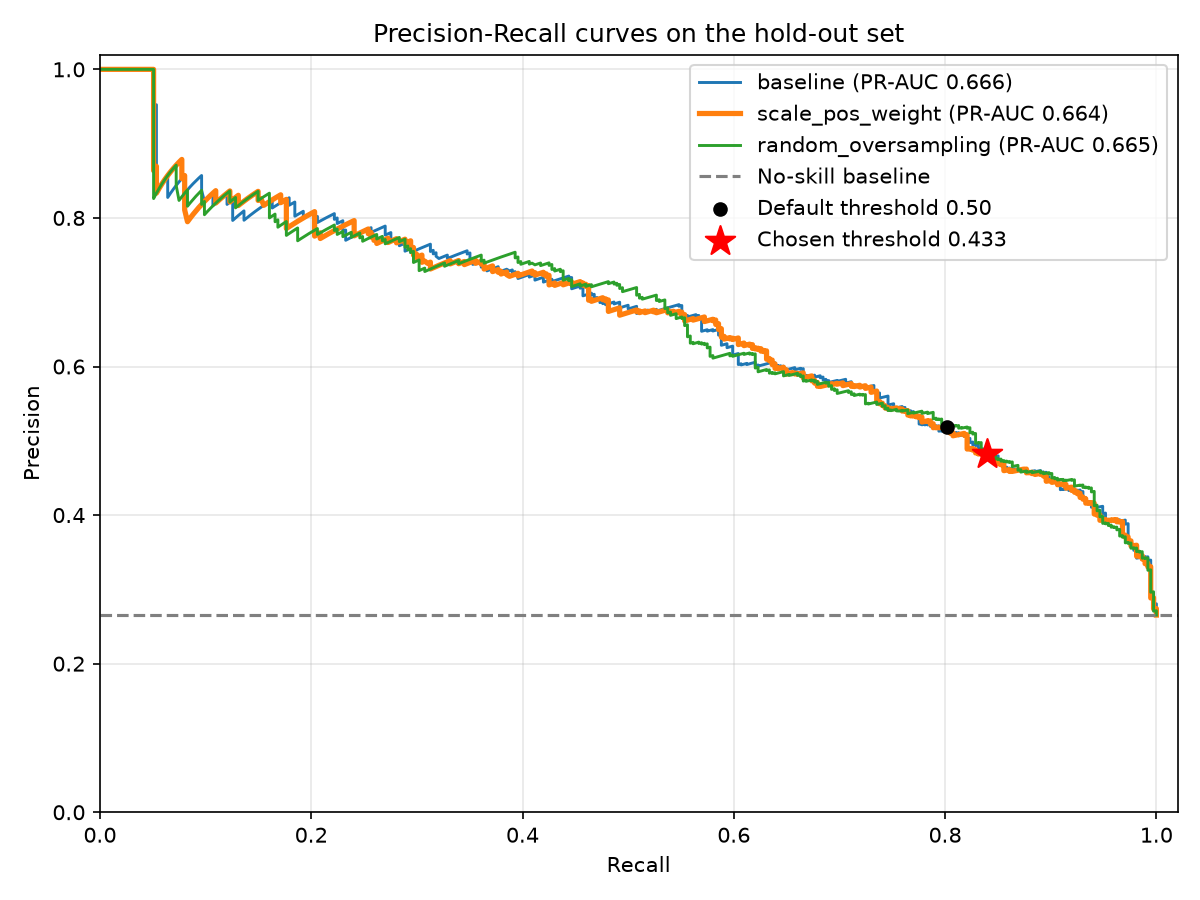

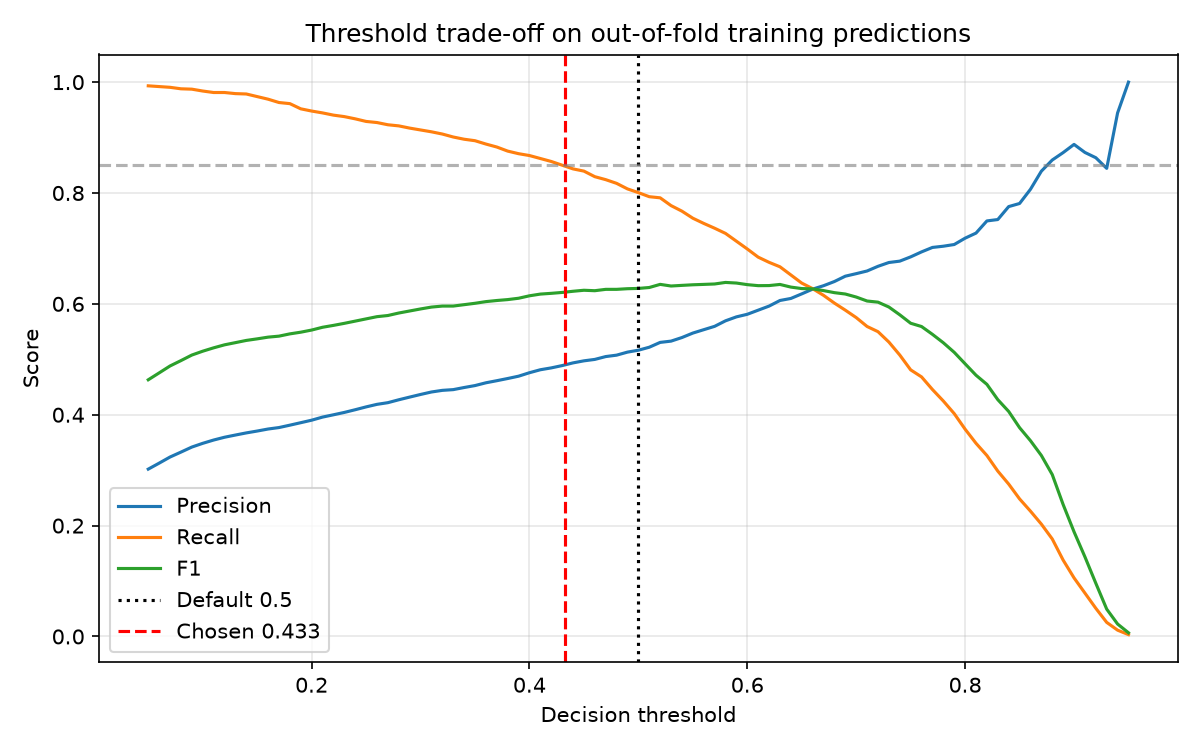

In [12]:
from IPython.display import Image, Markdown, display

display(Image(filename=str(OUTPUT_DIR / "pr_curves.png")))
display(Image(filename=str(OUTPUT_DIR / "threshold_tradeoff.png")))

## 13. Written deliverables

In [13]:
display(Markdown((BASE_DIR / "THRESHOLD_DECISION.md").read_text(encoding="utf-8")))
display(Markdown((BASE_DIR / "ERROR_ANALYSIS.md").read_text(encoding="utf-8")))

# Threshold Decision

## Business preference

The model is used to decide which customers receive a retention offer. Missing a customer who is about to leave (a false negative) costs that customer's future revenue, while contacting a customer who would have stayed (a false positive) only costs one offer. Recall is therefore prioritised over precision.

Decision rule: choose the threshold with the highest precision among all thresholds that keep recall at or above 85%.

## Imbalance strategy comparison

All three strategies were tuned with the same 5-fold stratified RandomizedSearchCV (25 candidates, scored by PR-AUC). Resampling happens only inside the training folds, so the hold-out set is never resampled. Metrics below are on the untouched hold-out set at the default 0.5 threshold. The strategy was selected by cross-validated PR-AUC on training data only.

| strategy | cv_pr_auc | precision | recall | f1 | roc_auc | pr_auc |
| --- | --- | --- | --- | --- | --- | --- |
| baseline | 0.6724 | 0.6760 | 0.5187 | 0.5870 | 0.8487 | 0.6660 |
| scale_pos_weight | 0.6713 | 0.5190 | 0.8021 | 0.6303 | 0.8476 | 0.6645 |
| random_oversampling | 0.6698 | 0.5274 | 0.7968 | 0.6347 | 0.8485 | 0.6646 |

Selected strategy: **scale_pos_weight**

Best hyperparameters:

- `colsample_bytree`: 0.85404
- `learning_rate`: 0.01064
- `max_depth`: 3
- `min_child_weight`: 8
- `n_estimators`: 563
- `subsample`: 0.68494

## How the threshold was chosen

The threshold was picked from out-of-fold predicted probabilities on the training data, so the hold-out set played no part in the choice. It was then applied once to the hold-out set.

Chosen threshold: **0.4328** (lower than the default 0.50).

| setting | threshold | precision | recall | f1 | tp | fp | fn | tn |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Train out-of-fold, default | 0.5000 | 0.5164 | 0.8007 | 0.6279 | 1197 | 1121 | 298 | 3018 |
| Train out-of-fold, chosen | 0.4328 | 0.4905 | 0.8502 | 0.6221 | 1271 | 1320 | 224 | 2819 |

## Hold-out results

| setting | threshold | precision | recall | f1 | tp | fp | fn | tn |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Hold-out, default | 0.5000 | 0.5190 | 0.8021 | 0.6303 | 300 | 278 | 74 | 757 |
| Hold-out, chosen | 0.4328 | 0.4823 | 0.8396 | 0.6127 | 314 | 337 | 60 | 698 |

Hold-out size: 1409 customers, 374 of them churners.

## What the threshold implies

Compared with the default threshold, 0.4328 flags +73 customers on the hold-out set and changes the number of caught churners by +14. The model's probabilities are not calibrated, particularly when class weighting is used, so the threshold is a ranking cutoff and should not be read as a literal probability of churn. If a retention offer is cheap relative to lost revenue the threshold should move down, and if offers are expensive it should move up.

## Figures

- `outputs/pr_curves.png`: precision-recall curves with the default and chosen operating points marked.
- `outputs/threshold_tradeoff.png`: precision, recall and F1 against the threshold on out-of-fold predictions.

## Caveats

Recall on the hold-out set can differ from the 85% target because the threshold was fitted on different data. With 374 churners in the hold-out set, small differences in recall are within normal sampling noise.


# Error Analysis

## Setup

- Model: `scale_pos_weight` strategy, decision threshold 0.4328
- Hold-out customers: 1409
- Confusion matrix: TP 314, FP 337, FN 60, TN 698
- Share of churners missed (false negative rate): 16.0%
- Share of stayers wrongly flagged (false positive rate): 32.6%

## Ten misclassified customers

The five most confident false negatives (churners given the lowest churn probability) and the five most confident false positives (stayers given the highest churn probability).

| customerID | error_type | proba | tenure | Contract | InternetService | PaymentMethod | MonthlyCharges | TechSupport |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 8580-QVLOC | False Negative | 0.025 | 72 | Two year | DSL | Credit card (automatic) | 92.450 | Yes |
| 3400-ESFUW | False Negative | 0.035 | 55 | Two year | DSL | Bank transfer (automatic) | 57.550 | Yes |
| 6598-RFFVI | False Negative | 0.076 | 2 | One year | No | Credit card (automatic) | 19.300 | No internet service |
| 3705-PSNGL | False Negative | 0.083 | 45 | One year | No | Electronic check | 20.400 | No internet service |
| 4464-JCOLN | False Negative | 0.093 | 2 | One year | No | Mailed check | 19.850 | No internet service |
| 4927-WWOOZ | False Positive | 0.922 | 2 | Month-to-month | Fiber optic | Electronic check | 91.450 | No |
| 2545-EBUPK | False Positive | 0.921 | 2 | Month-to-month | Fiber optic | Electronic check | 84.050 | No |
| 1628-BIZYP | False Positive | 0.921 | 1 | Month-to-month | Fiber optic | Electronic check | 85.000 | No |
| 8161-QYMTT | False Positive | 0.920 | 7 | Month-to-month | Fiber optic | Electronic check | 94.100 | No |
| 6630-UJZMY | False Positive | 0.913 | 4 | Month-to-month | Fiber optic | Electronic check | 83.250 | No |

## Grouping by shared characteristics

- **False Negatives (5 customers):** median tenure 45 months, most common contract One year (3 of 5), internet service No (3 of 5), payment method Credit card (automatic) (2 of 5), median monthly charge 20.40, mean predicted churn probability 0.06.
- **False Positives (5 customers):** median tenure 2 months, most common contract Month-to-month (5 of 5), internet service Fiber optic (5 of 5), payment method Electronic check (5 of 5), median monthly charge 85.00, mean predicted churn probability 0.92.

Counts by error type, contract and internet service:

| error_type | Contract | InternetService | customers |
| --- | --- | --- | --- |
| False Negative | One year | No | 3 |
| False Negative | Two year | DSL | 2 |
| False Positive | Month-to-month | Fiber optic | 5 |

## Patterns across the full hold-out set

Segments below have at least 30 customers and at least 15 customers of the relevant class.

### Where the model misses churners

1. Churners with Contract = One year are missed 72% of the time (26 of 36), against 16% overall.
2. Churners with InternetService = No are missed 56% of the time (14 of 25), against 16% overall.
3. Churners with tenure_band = 49-72 months are missed 54% of the time (19 of 35), against 16% overall.

| feature | value | customers | churners | fn_rate | stayers | fp_rate |
| --- | --- | --- | --- | --- | --- | --- |
| Contract | One year | 300 | 36 | 0.722 | 264 | 0.125 |
| InternetService | No | 312 | 25 | 0.560 | 287 | 0.077 |
| tenure_band | 49-72 months | 450 | 35 | 0.543 | 415 | 0.116 |
| PaymentMethod | Bank transfer (automatic) | 300 | 57 | 0.316 | 243 | 0.173 |
| tenure_band | 25-48 months | 304 | 64 | 0.281 | 240 | 0.275 |
| PaperlessBilling | No | 569 | 100 | 0.260 | 469 | 0.188 |
| InternetService | DSL | 484 | 97 | 0.258 | 387 | 0.245 |
| PaymentMethod | Credit card (automatic) | 309 | 51 | 0.255 | 258 | 0.205 |

### Where the model raises false alarms

1. Customers who stay with Contract = Month-to-month are wrongly flagged 68% of the time (303 of 444), against 33% overall.
2. Customers who stay with PaymentMethod = Electronic check are wrongly flagged 65% of the time (173 of 268), against 33% overall.
3. Customers who stay with tenure_band = 0-12 months are wrongly flagged 65% of the time (151 of 234), against 33% overall.

| feature | value | customers | churners | fn_rate | stayers | fp_rate |
| --- | --- | --- | --- | --- | --- | --- |
| Contract | Month-to-month | 773 | 329 | 0.076 | 444 | 0.682 |
| PaymentMethod | Electronic check | 474 | 206 | 0.073 | 268 | 0.646 |
| tenure_band | 0-12 months | 449 | 215 | 0.088 | 234 | 0.645 |
| InternetService | Fiber optic | 613 | 252 | 0.083 | 361 | 0.609 |
| SeniorCitizen | 1 | 222 | 98 | 0.041 | 124 | 0.573 |
| tenure_band | 13-24 months | 206 | 60 | 0.067 | 146 | 0.493 |
| PaperlessBilling | Yes | 840 | 274 | 0.124 | 566 | 0.440 |
| SeniorCitizen | 0 | 1187 | 276 | 0.203 | 911 | 0.292 |

## Takeaways

- The segments above show where errors concentrate. A segment with a miss rate far above the overall rate is where the model has the least signal.
- Segment-level rates rest on small counts, so treat them as leads to investigate rather than firm conclusions.
- Full per-segment numbers are in `outputs/segment_error_rates.csv` and the ten sampled customers are in `outputs/misclassified_sample.csv`.


## 14. Download results

In [15]:
import shutil

bundle = BASE_DIR / "results_bundle"
bundle.mkdir(exist_ok=True)
for name in ["THRESHOLD_DECISION.md", "ERROR_ANALYSIS.md"]:
    shutil.copy(BASE_DIR / name, bundle / name)
for folder in ["outputs", "models"]:
    shutil.copytree(BASE_DIR / folder, bundle / folder, dirs_exist_ok=True)
archive = shutil.make_archive(str(BASE_DIR / "churn_results"), "zip", str(bundle))
print("Saved to:", archive)

Saved to: c:\Users\HP 840 G5\OneDrive\Desktop\churn_project\churn_results.zip
